In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
print("Setup done")

Setup done


In [2]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv("heart.csv")
print(df.shape)
df.head()

Saving heart.csv to heart (1).csv
(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
df.info()
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Heart disease counts:\n", df["HeartDisease"].value_counts())
print("Zero cholesterol:", (df["Cholesterol"] == 0).sum())
print("Zero RestingBP:", (df["RestingBP"] == 0).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB
Missing values:
 Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpe

In [4]:
print((df["Cholesterol"] == 0).sum())
print((df["RestingBP"] == 0).sum())

172
1


In [5]:
df = df[df["RestingBP"] > 0].copy()
df.shape

(917, 12)

In [6]:
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)
df["Cholesterol"].isnull().sum()

np.int64(171)

In [7]:
print(df.duplicated().sum())
print(df["HeartDisease"].mean() * 100)

0
55.288985823336965


In [8]:
df.groupby(df["Cholesterol"].isnull())["HeartDisease"].mean() * 100

,HeartDisease
Cholesterol,
False,47.721180
True,88.304094


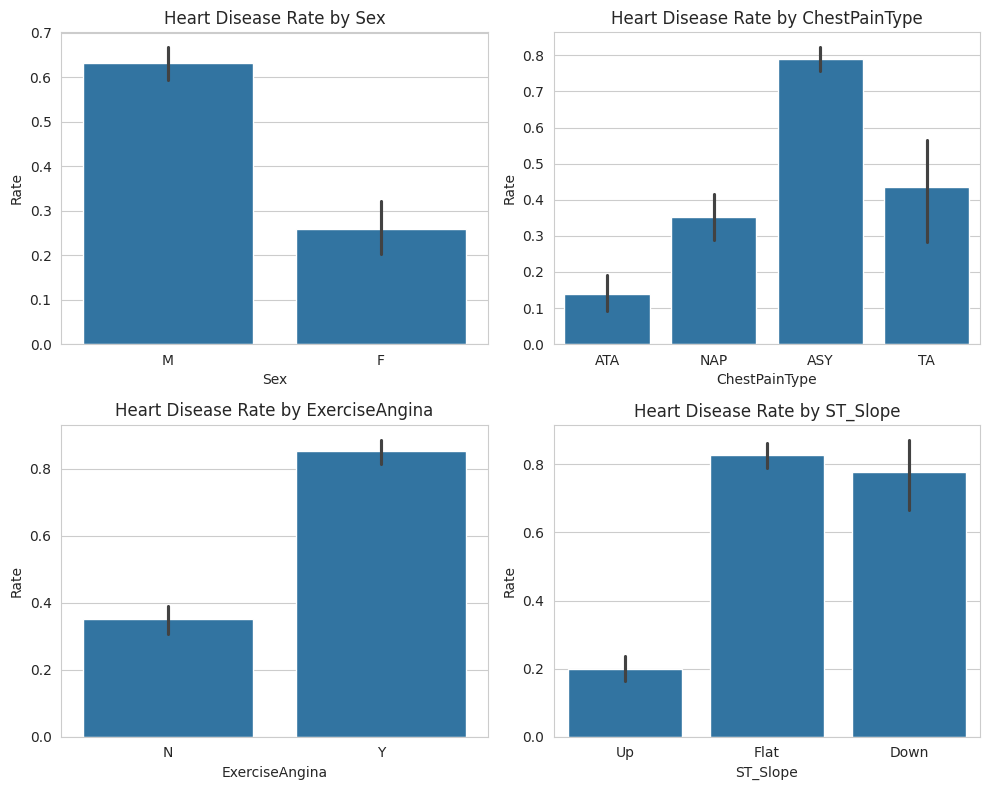

In [9]:
cat_cols = ["Sex", "ChestPainType", "ExerciseAngina", "ST_Slope"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col in zip(axes.flatten(), cat_cols):
    sns.barplot(x=col, y="HeartDisease", data=df, ax=ax)
    ax.set_title(f"Heart Disease Rate by {col}")
    ax.set_ylabel("Rate")
plt.tight_layout()
plt.show()

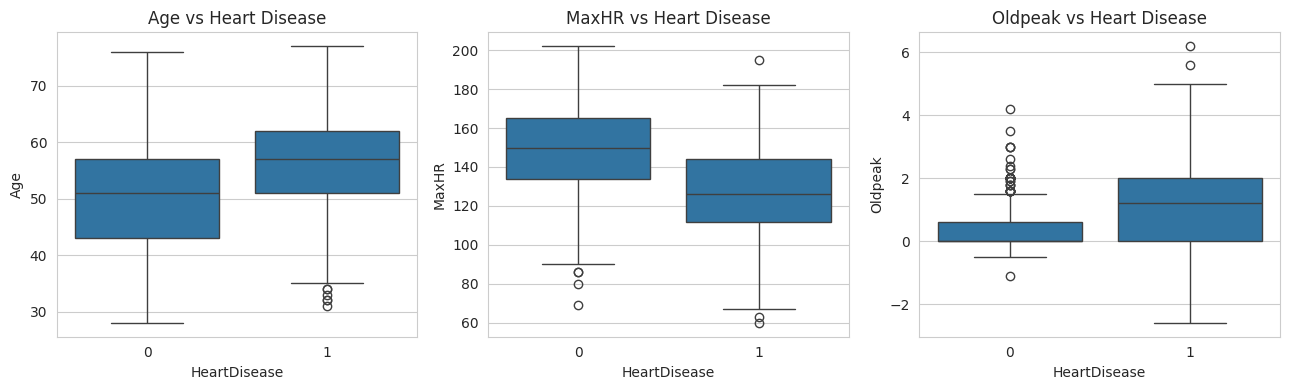

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["Age", "MaxHR", "Oldpeak"]):
    sns.boxplot(x="HeartDisease", y=col, data=df, ax=ax)
    ax.set_title(f"{col} vs Heart Disease")
plt.tight_layout()
plt.show()

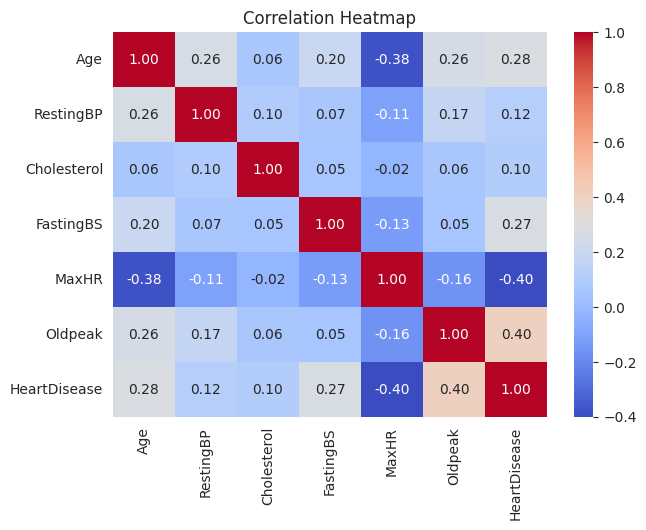

In [11]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [12]:
df["Chol_Missing"] = df["Cholesterol"].isnull().astype(int)
df["Chol_Missing"].sum()

np.int64(171)

In [13]:
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)
df_encoded.shape
df_encoded.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Chol_Missing,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289.0,0,172,0.0,0,0,1,1,0,0,1,0,0,0,1
1,49,160,180.0,0,156,1.0,1,0,0,0,1,0,1,0,0,1,0
2,37,130,283.0,0,98,0.0,0,0,1,1,0,0,0,1,0,0,1
3,48,138,214.0,0,108,1.5,1,0,0,0,0,0,1,0,1,1,0
4,54,150,195.0,0,122,0.0,0,0,1,0,1,0,1,0,0,0,1


In [14]:
X = df_encoded.drop("HeartDisease", axis=1)
y = df_encoded["HeartDisease"]

print(X.shape)
print(y.shape)

(917, 16)
(917,)


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape)
print(X_test.shape)
print(y_train.mean())
print(y_test.mean())

(733, 16)
(184, 16)
0.5525238744884038
0.5543478260869565


In [16]:
chol_median = X_train["Cholesterol"].median()
print(chol_median)

X_train["Cholesterol"] = X_train["Cholesterol"].fillna(chol_median)
X_test["Cholesterol"] = X_test["Cholesterol"].fillna(chol_median)

print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

239.0
0
0


In [17]:
from sklearn.preprocessing import StandardScaler

num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

X_train_scaled[num_cols].describe().round(2)

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
count,733.00,733.00,733.00,733.00,733.00
mean,-0.00,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.62,-2.24,-2.96,-3.00,-3.24
25%,-0.72,-0.71,-0.55,-0.69,-0.81
50%,0.13,-0.16,-0.11,0.05,-0.35
75%,0.66,0.38,0.45,0.75,0.59
max,2.46,3.66,6.64,2.55,4.98


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, lr_pred))
print(classification_report(y_test, lr_pred))

Accuracy: 0.8858695652173914
              precision    recall  f1-score   support

           0       0.89      0.85      0.87        82
           1       0.89      0.91      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.89      0.89      0.89       184



In [19]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

Accuracy: 0.8804347826086957
              precision    recall  f1-score   support

           0       0.87      0.87      0.87        82
           1       0.89      0.89      0.89       102

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184



In [20]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pipe_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

for name, model in [("Logistic Regression", pipe_lr), ("Random Forest", rf)]:
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="recall")
    print(name, "recall:", scores.mean().round(2), "+/-", scores.std().round(2))

Logistic Regression recall: 0.88 +/- 0.04
Random Forest recall: 0.89 +/- 0.04


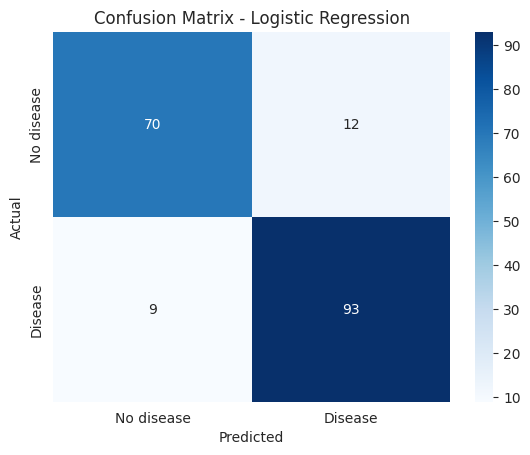

In [21]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, lr_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No disease", "Disease"],
            yticklabels=["No disease", "Disease"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

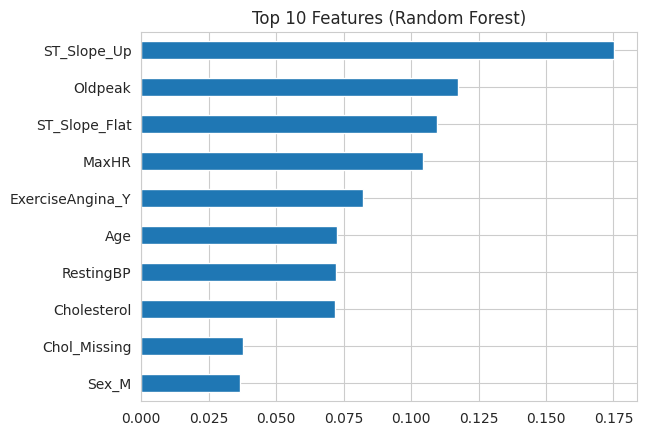

In [22]:
importances = pd.Series(rf.feature_importances_, index=X.columns)
importances.sort_values().tail(10).plot(kind="barh")
plt.title("Top 10 Features (Random Forest)")
plt.show()

In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = {"Logistic Regression": lr_pred, "Random Forest": rf_pred}
rows = []
for name, pred in models.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })
pd.DataFrame(rows).round(2)

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.89,0.89,0.91,0.90
1,Random Forest,0.88,0.89,0.89,0.89


## Conclusion
- About 55% of patients have heart disease.
- Patients with missing cholesterol records had an 88% heart disease rate vs 48% for recorded ones, likely a data-collection quirk.
- Higher risk: flat ST slope, higher Oldpeak, exercise angina, older age, lower maximum heart rate.
- Top Random Forest features: ST slope, Oldpeak, MaxHR, ExerciseAngina.
- Logistic Regression is the final model: 0.89 accuracy, 0.89 precision and 0.91 recall on 184 held-out patients (it caught 93 of 102 patients with heart disease and missed 9).
- Random Forest performed similarly (0.88 accuracy, 0.89 recall), and 5-fold cross-validation recall was 0.88 vs 0.89, so the two models are effectively tied.
- This is a learning project, not a medical diagnostic tool.